# TN4 (Hash Encoding): Nghiên cứu loại trừ số mức độ phân giải L của Multiresolution Hash Encoding

Kịch bản **TN4_HashEncoding** giữ nguyên mọi siêu tham số của `instant-ngp` (`30.000` bước, `seed = 42`, `max_res = 2048`, `log2_hashmap_size = 19`, `Occupancy Grid ON`) trên cảnh `mipnerf360/garden` (`images_8`) và lần lượt thay đổi số mức bảng băm sang **$L = 4$** và **$L = 8$**, đối chiếu với cấu hình mặc định **$L = 16$** của TN1.

In [1]:
import hashlib
import importlib.metadata as metadata
import importlib.util
import json
import os
import re
import shutil
import subprocess
import sys
import time
from datetime import datetime, timezone
from pathlib import Path

import torch

os.environ["MPLBACKEND"] = "Agg"
SEED = 42
NERFSTUDIO_COMMIT = "50e0e3c70c775e89333256213363badbf074f29d"
repo = Path("/kaggle/working/nerfstudio")
print("Python:", sys.version)
print("PyTorch:", torch.__version__)
print("PyTorch CUDA:", torch.version.cuda)
print("CUDA available:", torch.cuda.is_available())
assert torch.cuda.is_available(), "Enable a Kaggle GPU in Notebook Settings."
print("GPU:", torch.cuda.get_device_name(0))

nvcc = shutil.which("nvcc")
if nvcc is None:
    raise RuntimeError("nvcc is unavailable; tiny-cuda-nn needs the CUDA Toolkit to compile.")
nvcc_info = subprocess.run([nvcc, "--version"], text=True, capture_output=True, check=True).stdout
print(nvcc_info)
toolkit_match = re.search(r"release (\d+\.\d+)", nvcc_info)
if toolkit_match and torch.version.cuda and toolkit_match.group(1) != torch.version.cuda:
    print("CUDA toolkit and PyTorch CUDA versions differ; continuing with the Kaggle-provided runtime.")

if not repo.exists():
    subprocess.run([
        "git", "clone", "--filter=blob:none", "--no-checkout",
        "https://github.com/nerfstudio-project/nerfstudio.git", str(repo)
    ], check=True)
subprocess.run(["git", "-C", str(repo), "fetch", "--depth", "1", "origin", NERFSTUDIO_COMMIT], check=True)
subprocess.run(["git", "-C", str(repo), "checkout", "--force", "--detach", NERFSTUDIO_COMMIT], check=True)
nerfstudio_commit = subprocess.run(
    ["git", "-C", str(repo), "rev-parse", "HEAD"], text=True, capture_output=True, check=True
).stdout.strip()
assert nerfstudio_commit == NERFSTUDIO_COMMIT
print("Pinned Nerfstudio commit:", nerfstudio_commit)


Python: 3.13.16 (main, Oct  1 2026, 15:40:24) [GCC 13.3.0]
PyTorch: 2.11.0+cu130
PyTorch CUDA: 13.0
CUDA available: True
GPU: Tesla T4
nvcc: NVIDIA (R) Cuda compiler driver
Copyright (c) 2005-2025 NVIDIA Corporation
Built on Wed_Aug_20_01:58:59_PM_PDT_2025
Cuda compilation tools, release 13.0, V13.0.88
Build cuda_13.0.r13.0/compiler.36424714_0



Cloning into '/kaggle/working/nerfstudio'...
From https://github.com/nerfstudio-project/nerfstudio
 * branch              50e0e3c70c775e89333256213363badbf074f29d -> FETCH_HEAD


Pinned Nerfstudio commit: 50e0e3c70c775e89333256213363badbf074f29d


HEAD is now at 50e0e3c7 Add image tiling option to ColmapDataParser to use less memory (#3685)


In [2]:
# Keep Kaggle's preinstalled PyTorch/CUDA. Pin Pillow below 12 for Nerfstudio 1.1.5.
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "ninja", "packaging", "Pillow<12"], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", str(repo)], check=True)
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "Pillow<12"], check=True)

# Ensure the newly editable-installed nerfstudio package takes precedence over the CWD folder name.
import importlib
if str(repo) not in sys.path:
    sys.path.insert(0, str(repo))
for mod_name in [k for k in list(sys.modules) if k == "nerfstudio" or k.startswith("nerfstudio.")]:
    sys.modules.pop(mod_name, None)
importlib.invalidate_caches()
import nerfstudio.data.utils.colmap_parsing_utils as _ns_colmap_check
print("Verified nerfstudio package:", _ns_colmap_check.__file__)

# Patch NerfAcc 0.5.2 scan.cu for CUDA 13 compatibility.
nerfacc_spec = importlib.util.find_spec("nerfacc")
if nerfacc_spec is None or nerfacc_spec.origin is None:
    raise RuntimeError("nerfacc was not installed with Nerfstudio.")
nerfacc_root = Path(nerfacc_spec.origin).parent
scan_file = nerfacc_root / "cuda" / "csrc" / "scan.cu"
scan_text = scan_file.read_text(encoding="utf-8")
if "#include <thrust/functional.h>" not in scan_text:
    scan_text = "#include <thrust/functional.h>\n" + scan_text
if "cub::Equality()" in scan_text:
    scan_text = scan_text.replace("cub::Equality()", "thrust::equal_to<int64_t>()")
elif "thrust::equal_to<int64_t>()" not in scan_text:
    raise RuntimeError(f"Unexpected NerfAcc scan.cu source: {scan_file}")
scan_file.write_text(scan_text, encoding="utf-8")
print("CUDA 13 compatible NerfAcc scan:", scan_file)

# Patch Nerfstudio eval_utils.py for PyTorch 2.6+ weights_only=False.
eval_utils_file = repo / "nerfstudio" / "utils" / "eval_utils.py"
eval_utils_text = eval_utils_file.read_text(encoding="utf-8")
old_load = 'torch.load(load_path, map_location="cpu")'
compatible_load = 'torch.load(load_path, map_location="cpu", weights_only=False)'
if old_load in eval_utils_text:
    eval_utils_text = eval_utils_text.replace(old_load, compatible_load)
elif compatible_load not in eval_utils_text:
    raise RuntimeError(f"Could not apply PyTorch checkpoint compatibility patch: {eval_utils_file}")
eval_utils_file.write_text(eval_utils_text, encoding="utf-8")
print("Nerfstudio checkpoint load compatibility:", eval_utils_file)

# Patch instant_ngp.py to expose num_levels (L) on InstantNGPModelConfig for Hash Encoding ablation.
ngp_file = repo / "nerfstudio" / "models" / "instant_ngp.py"
ngp_text = ngp_file.read_text(encoding="utf-8")
cfg_anchor = '    max_res: int = 2048\n    """Maximum resolution of the hashmap for the base mlp."""'
cfg_patched = (
    '    num_levels: int = 16\n    """Number of levels L of the multiresolution hash encoding."""\n'
    + cfg_anchor
)
if 'num_levels: int = 16' not in ngp_text:
    assert cfg_anchor in ngp_text, "Could not locate max_res anchor in instant_ngp.py"
    ngp_text = ngp_text.replace(cfg_anchor, cfg_patched, 1)

field_anchor = '            log2_hashmap_size=self.config.log2_hashmap_size,\n            max_res=self.config.max_res,'
field_patched = (
    '            num_levels=self.config.num_levels,\n' + field_anchor
)
if 'num_levels=self.config.num_levels,' not in ngp_text:
    assert field_anchor in ngp_text, "Could not locate NerfactoField call anchor in instant_ngp.py"
    ngp_text = ngp_text.replace(field_anchor, field_patched, 1)
ngp_file.write_text(ngp_text, encoding="utf-8")

from nerfstudio.models.instant_ngp import InstantNGPModelConfig
assert InstantNGPModelConfig().num_levels == 16
print("Patched InstantNGPModelConfig to expose num_levels (L):", ngp_file)

# Build NVlabs tiny-cuda-nn v2.0 for active Kaggle GPU compute capability.
env = os.environ.copy()
major, minor = torch.cuda.get_device_capability(0)
env["TCNN_CUDA_ARCHITECTURES"] = f"{major}{minor}"
print("tiny-cuda-nn CUDA architecture:", env["TCNN_CUDA_ARCHITECTURES"])
ldconfig = subprocess.run(["ldconfig", "-p"], text=True, capture_output=True, check=False).stdout
driver_candidates = re.findall(r"\s+(\/\S*libcuda\.so\.1)\s*$", ldconfig, flags=re.MULTILINE)
driver_candidates += [
    "/usr/lib/x86_64-linux-gnu/libcuda.so.1",
    "/usr/lib64/libcuda.so.1",
    "/usr/local/nvidia/lib64/libcuda.so.1",
]
driver_lib = next((Path(path) for path in driver_candidates if Path(path).is_file()), None)
if driver_lib is None:
    raise RuntimeError("Could not locate CUDA driver library libcuda.so.1.")
link_dir = Path("/kaggle/working/cuda-link")
link_dir.mkdir(parents=True, exist_ok=True)
cuda_link = link_dir / "libcuda.so"
if cuda_link.exists() or cuda_link.is_symlink():
    cuda_link.unlink()
cuda_link.symlink_to(driver_lib)
env["LIBRARY_PATH"] = str(link_dir) + os.pathsep + env.get("LIBRARY_PATH", "")

tcnn_repo = Path("/kaggle/working/tiny-cuda-nn")
if tcnn_repo.exists():
    current_tcnn_tag = subprocess.run(
        ["git", "-C", str(tcnn_repo), "describe", "--tags", "--exact-match"],
        text=True, capture_output=True, check=False,
    )
    if current_tcnn_tag.returncode or current_tcnn_tag.stdout.strip() != "v2.0":
        shutil.rmtree(tcnn_repo)
if not tcnn_repo.exists():
    subprocess.run([
        "git", "clone", "--recursive", "--depth", "1", "--branch", "v2.0",
        "https://github.com/NVlabs/tiny-cuda-nn.git", str(tcnn_repo)
    ], check=True)
tcnn_commit = subprocess.run(
    ["git", "-C", str(tcnn_repo), "rev-parse", "HEAD"], text=True, capture_output=True, check=True
).stdout.strip()
subprocess.run([
    sys.executable, "-m", "pip", "install", "-q", "--no-build-isolation",
    str(tcnn_repo / "bindings" / "torch")
], check=True, env=env)

import tinycudann as tcnn
encoding = tcnn.Encoding(3, {
    "otype": "HashGrid", "n_levels": 2, "n_features_per_level": 2,
    "log2_hashmap_size": 4, "base_resolution": 4, "per_level_scale": 2.0,
}).cuda()
with torch.no_grad():
    encoded = encoding(torch.rand((8, 3), device="cuda"))
assert encoded.shape == (8, 4)
print("tiny-cuda-nn commit:", tcnn_commit)
print("tiny-cuda-nn CUDA smoke check:", tuple(encoded.shape))


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
dopamine-rl 4.1.2 requires gym<=0.25.2, but you have gym 0.26.2 which is incompatible.
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
grpcio-tools 1.85.1 requires protobuf<8.0.0,>=7.35.1, but you have protobuf 4.25.9 which is incompatible.
a2a-sdk 1.3.1 requires protobuf>=5.29.5, but you have protobuf 4.25.9 which is incompatible.
onnx 1.23.2 requires protobuf>=6.31.1, but you have protobuf 4.25.9 which is incompatible.
google-cloud-texttospeech 2.38.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 4.25.9 which is incompatible.
google-cloud-vision 3.16.0 requires protobuf<8.0.0,>=6.33.5, but you have protobuf 4.25.9 which is incompatible.
google-cloud-videointelligence 2.21.0 req

Verified nerfstudio package: /kaggle/working/nerfstudio/nerfstudio/data/utils/colmap_parsing_utils.py
CUDA 13 compatible NerfAcc scan: /usr/local/lib/python3.13/dist-packages/nerfacc/cuda/csrc/scan.cu
Nerfstudio checkpoint load compatibility: /kaggle/working/nerfstudio/nerfstudio/utils/eval_utils.py


/kaggle/working/nerfstudio/nerfstudio/field_components/activations.py:32: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd(cast_inputs=torch.float32)
/kaggle/working/nerfstudio/nerfstudio/field_components/activations.py:38: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @custom_bwd
Cloning into '/kaggle/working/tiny-cuda-nn'...


Patched InstantNGPModelConfig to expose num_levels (L): /kaggle/working/nerfstudio/nerfstudio/models/instant_ngp.py
tiny-cuda-nn CUDA architecture: 75


Note: switching to '3c7931caab7b691c6f30dffe20952ed727d935b9'.

You are in 'detached HEAD' state. You can look around, make experimental
changes and commit them, and you can discard any commits you make in this
state without impacting any branches by switching back to a branch.

If you want to create a new branch to retain commits you create, you may
do so (now or later) by using -c with the switch command. Example:

  git switch -c <new-branch-name>

Or undo this operation with:

  git switch -

Turn off this advice by setting config variable advice.detachedHead to false

Submodule 'dependencies/cmrc' (https://github.com/vector-of-bool/cmrc) registered for path 'dependencies/cmrc'
Submodule 'dependencies/cutlass' (https://github.com/NVIDIA/cutlass) registered for path 'dependencies/cutlass'
Submodule 'dependencies/fmt' (https://github.com/fmtlib/fmt) registered for path 'dependencies/fmt'
Cloning into '/kaggle/working/tiny-cuda-nn/dependencies/cmrc'...
Cloning into '/kaggle/working/ti

Submodule path 'dependencies/cmrc': checked out '952ffddba731fc110bd50409e8d2b8a06abbd237'
Submodule path 'dependencies/cutlass': checked out '1eb6355182a5124639ce9d3ff165732a94ed9a70'
Submodule path 'dependencies/fmt': checked out 'b0c8263cb26ea178d3a5df1b984e1a61ef578950'
tiny-cuda-nn commit: 3c7931caab7b691c6f30dffe20952ed727d935b9
tiny-cuda-nn CUDA smoke check: (8, 4)


In [3]:
input_dir = Path("/kaggle/input/mipnerf360-garden-images8")
if not input_dir.exists():
    try:
        import kagglehub
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", "kagglehub"], check=True)
        import kagglehub
    input_dir = Path(kagglehub.dataset_download("nminhkhoa24120073/mipnerf360-garden-images8/versions/1"))

def is_scene_root(path: Path) -> bool:
    return (path / "images_8").is_dir() and all(
        (path / "sparse" / "0" / filename).is_file()
        for filename in ("cameras.bin", "images.bin", "points3D.bin")
    )

if not is_scene_root(input_dir):
    possible_roots = [path.parent for path in input_dir.rglob("images_8") if is_scene_root(path.parent)]
    if len(possible_roots) != 1:
        raise RuntimeError(f"Expected one Garden dataset root with images_8 and sparse/0; found {possible_roots}")
    input_dir = possible_roots[0]

scene = Path("/kaggle/working/mipnerf360-garden")
if not scene.exists():
    shutil.copytree(input_dir, scene)
images_8_dir = scene / "images_8"
images = sorted(path for path in images_8_dir.iterdir() if path.is_file())
if len(images) != 185:
    raise RuntimeError(f"Expected 185 images in images_8, found {len(images)}")
assert is_scene_root(scene)

images_dir = scene / "images"
if not images_dir.exists():
    shutil.copytree(images_8_dir, images_dir)
image_names = {path.name for path in images}
parser_image_names = {path.name for path in images_dir.iterdir() if path.is_file()}
if image_names != parser_image_names:
    raise RuntimeError("The images and images_8 directories must contain the same filenames.")

from PIL import Image
from nerfstudio.data.utils.colmap_parsing_utils import read_cameras_binary, read_images_binary

colmap_dir = scene / "sparse" / "0"
cameras = read_cameras_binary(colmap_dir / "cameras.bin")
colmap_images = read_images_binary(colmap_dir / "images.bin")
colmap_image_names = {record.name for record in colmap_images.values()}
if colmap_image_names != image_names:
    raise RuntimeError("COLMAP and images_8 filenames differ.")

for record in colmap_images.values():
    camera = cameras[record.camera_id]
    with Image.open(images_8_dir / record.name) as image:
        image_size = image.size
    expected_size = (camera.width // 8, camera.height // 8)
    if image_size != expected_size:
        raise RuntimeError(f"Image/COLMAP mismatch for {record.name}: {image_size} vs {expected_size}")

digest = hashlib.sha256()
for path in [colmap_dir / "cameras.bin", colmap_dir / "images.bin", colmap_dir / "points3D.bin", *images]:
    digest.update(path.relative_to(scene).as_posix().encode("utf-8"))
    with path.open("rb") as content:
        for chunk in iter(lambda: content.read(1024 * 1024), b""):
            digest.update(chunk)
dataset_fingerprint = digest.hexdigest()
print("Validated 185 images against COLMAP (downscale factor 8).")
print("Dataset:", scene, "| fingerprint:", dataset_fingerprint)


Validated 185 images against COLMAP (downscale factor 8).
Dataset: /kaggle/working/mipnerf360-garden | fingerprint: 04f971ed3fc35627f86bd5ea921c199bfd9f366af935e1e8c8d5111e39683e4e


In [4]:
def checkpoint_step(path: Path) -> int:
    match = re.fullmatch(r"step-(\d+)\.ckpt", path.name)
    if match is None:
        raise RuntimeError(f"Unexpected checkpoint filename: {path.name}")
    return int(match.group(1))

def package_version(name: str) -> str | None:
    try:
        return metadata.version(name)
    except metadata.PackageNotFoundError:
        return None

def run_training_and_archive(
    exp_slug: str,
    method: str,
    extra_model_args: list[str],
    iterations: int = 30000,
) -> dict:
    os.chdir(repo)
    run_id = datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
    output_root = Path("/kaggle/working/outputs") / f"{exp_slug}-{run_id}"
    train_command = [
        "ns-train", method,
        "--machine.num-devices", "1",
        "--machine.seed", str(SEED),
        "--max-num-iterations", str(iterations),
        "--steps-per-save", "2000",
        "--steps-per-eval-all-images", str(iterations),
        "--logging.steps-per-log", "100",
        "--viewer.quit-on-train-completion", "True",
        "--output-dir", str(output_root),
        "--data", str(scene),
        *extra_model_args,
        "colmap", "--images-path", "images", "--colmap-path", "sparse/0",
        "--downscale-factor", "8", "--downscale-rounding-mode", "floor",
        "--eval-mode", "interval", "--eval-interval", "8",
    ]
    print(f"=== [{exp_slug}] Running: ===", flush=True)
    print(" ".join(train_command), flush=True)
    train_started_utc = datetime.now(timezone.utc).isoformat()
    train_started = time.perf_counter()
    train_log_path = Path(f"/kaggle/working/training-{exp_slug}.log")
    with train_log_path.open("w", encoding="utf-8") as log_file:
        process = subprocess.Popen(
            train_command, stdout=subprocess.PIPE, stderr=subprocess.STDOUT,
            text=True, bufsize=1, env={**os.environ, "PYTHONUNBUFFERED": "1"},
        )
        assert process.stdout is not None
        for line in process.stdout:
            print(line, end="", flush=True)
            log_file.write(line)
            log_file.flush()
        rc = process.wait()
    training_seconds = time.perf_counter() - train_started
    if rc:
        raise subprocess.CalledProcessError(rc, train_command)

    candidates = list(output_root.rglob("step-*.ckpt"))
    if not candidates:
        raise RuntimeError(f"No checkpoint found under {output_root}")
    checkpoint_path = max(candidates, key=checkpoint_step)
    saved_step = checkpoint_step(checkpoint_path)
    if saved_step < iterations - 1:
        raise RuntimeError(f"Expected step {iterations - 1}, found {saved_step}")
    config_path = checkpoint_path.parents[1] / "config.yml"
    assert config_path.is_file(), f"Config not found: {config_path}"

    artifacts = Path("/kaggle/working/experiment-artifacts") / exp_slug
    ckpt_dir = artifacts / "checkpoints"
    ckpt_dir.mkdir(parents=True, exist_ok=True)
    saved_ckpt = ckpt_dir / checkpoint_path.name
    shutil.copy2(checkpoint_path, saved_ckpt)
    shutil.copy2(config_path, artifacts / "config.yml")
    shutil.copy2(train_log_path, artifacts / "training.log")
    gpu_details = subprocess.run(
        ["nvidia-smi", "--query-gpu=name,driver_version,memory.total", "--format=csv"],
        text=True, capture_output=True, check=False,
    ).stdout.strip()
    meta = {
        "experiment": exp_slug,
        "run_id": run_id,
        "started_utc": train_started_utc,
        "training_seconds": training_seconds,
        "seed": SEED,
        "method": method,
        "iterations": iterations,
        "checkpoint_step": saved_step,
        "dataset_fingerprint": dataset_fingerprint,
        "gpu": torch.cuda.get_device_name(0),
        "gpu_driver": gpu_details,
        "python": sys.version,
        "torch": torch.__version__,
        "torch_cuda": torch.version.cuda,
        "nerfstudio_commit": nerfstudio_commit,
        "tiny_cuda_nn_commit": tcnn_commit,
        "nerfacc_version": package_version("nerfacc"),
        "pillow_version": package_version("Pillow"),
        "command": train_command,
        "config": str(config_path),
        "saved_checkpoint": str(saved_ckpt),
    }
    (artifacts / "run-metadata.json").write_text(json.dumps(meta, indent=2), encoding="utf-8")
    print(f"[{exp_slug}] Finished in {training_seconds / 60:.2f} min | step={saved_step}", flush=True)
    return {
        "artifacts": artifacts,
        "config_path": config_path,
        "saved_checkpoint": saved_ckpt,
        "training_seconds": training_seconds,
    }


In [5]:
%%writefile /kaggle/working/evaluate_experiment.py
"""Evaluate a Nerfstudio checkpoint and export image, timing, and field-query metrics.

The query count is the number of sampled 3D positions passed through Instant-NGP's
neural field during rendering. It is not a count of HTTP or Internet requests.
"""

from __future__ import annotations

import argparse
import csv
import json
import math
import statistics
import time
from pathlib import Path
from typing import Any

import torch
import torchvision.utils as vutils


def _mean(values: list[float]) -> float:
    return statistics.fmean(values) if values else float("nan")


def _std(values: list[float]) -> float:
    return statistics.pstdev(values) if len(values) > 1 else 0.0


def _write_csv(path: Path, rows: list[dict[str, Any]], fields: list[str]) -> None:
    with path.open("w", newline="", encoding="utf-8") as handle:
        writer = csv.DictWriter(handle, fieldnames=fields, extrasaction="ignore")
        writer.writeheader()
        writer.writerows(rows)


def _write_markdown(path: Path, summary: dict[str, Any]) -> None:
    title = summary.get("experiment_label") or f"{summary.get('method', 'model')} evaluation"
    rows = [
        ("Method", summary["method"]),
        ("Checkpoint step", summary["checkpoint_step"]),
        ("Held-out images", summary["num_images"]),
        ("PSNR (dB), mean ± std", f"{summary['psnr_mean']:.4f} ± {summary['psnr_std']:.4f}"),
        ("SSIM, mean ± std", f"{summary['ssim_mean']:.4f} ± {summary['ssim_std']:.4f}"),
        ("LPIPS, mean ± std", f"{summary['lpips_mean']:.4f} ± {summary['lpips_std']:.4f}"),
        ("Evaluation time (s)", f"{summary['evaluation_seconds']:.3f}"),
        ("Inference time (s)", f"{summary['inference_seconds']:.3f}"),
        ("Mean render time (ms/image)", f"{summary['mean_render_ms_per_image']:.3f}"),
        ("Images / second", f"{summary['images_per_second']:.4f}"),
        ("Rays / second", f"{summary['rays_per_second']:.2f}"),
        ("Rays evaluated", summary["total_rays"]),
        ("Field sample queries", summary["field_sample_queries_total"]),
        ("Field sample queries / ray", f"{summary['field_sample_queries_per_ray']:.4f}"),
        ("Peak GPU memory (MiB)", f"{summary['peak_gpu_memory_mib']:.2f}"),
        ("Model parameters", summary["num_parameters"]),
        ("Checkpoint size (MiB)", f"{summary['checkpoint_size_mib']:.2f}"),
    ]
    if summary.get("training_seconds") is not None:
        rows.insert(7, ("Training time (s)", f"{summary['training_seconds']:.3f}"))
    with path.open("w", encoding="utf-8") as handle:
        handle.write(f"# {title}\n\n")
        handle.write("| Metric | Value |\n|---|---:|\n")
        for name, value in rows:
            handle.write(f"| {name} | {value} |\n")
        handle.write(f"\n{summary['query_count_definition']}\n")


def _infer_static_samples_per_ray(model: Any) -> tuple[int, int, int] | None:
    """Return (total_per_ray, proposal_per_ray, nerf_per_ray) for proposal-based models like Nerfacto."""
    cfg = getattr(model, "config", None)
    if cfg is None:
        return None
    nerf_n = getattr(cfg, "num_nerf_samples_per_ray", None)
    prop_n = getattr(cfg, "num_proposal_samples_per_ray", None)
    if nerf_n is not None and prop_n is not None:
        prop_total = int(sum(prop_n))
        nerf_total = int(nerf_n)
        return (prop_total + nerf_total, prop_total, nerf_total)
    coarse_n = getattr(cfg, "num_coarse_samples", None)
    fine_n = getattr(cfg, "num_importance_samples", None)
    if coarse_n is not None and fine_n is not None:
        return (int(coarse_n) + int(fine_n), int(coarse_n), int(fine_n))
    return None


def main() -> None:
    parser = argparse.ArgumentParser(description=__doc__)
    parser.add_argument("--config", type=Path, required=True, help="Nerfstudio run's config.yml")
    parser.add_argument("--output-dir", type=Path, required=True)
    parser.add_argument("--training-seconds", type=float, default=None)
    parser.add_argument("--eval-rays-per-chunk", type=int, default=8192)
    parser.add_argument("--experiment-label", type=str, default=None)
    parser.add_argument("--save-comparisons", action=argparse.BooleanOptionalAction, default=True)
    args = parser.parse_args()

    if not args.config.is_file():
        parser.error(f"Config not found: {args.config}")
    args.output_dir.mkdir(parents=True, exist_ok=True)
    comparison_dir = args.output_dir / "comparisons"
    if args.save_comparisons:
        comparison_dir.mkdir(parents=True, exist_ok=True)

    from nerfstudio.utils.eval_utils import eval_setup

    config, pipeline, checkpoint_path, checkpoint_step = eval_setup(
        args.config,
        eval_num_rays_per_chunk=args.eval_rays_per_chunk,
        test_mode="test",
    )
    pipeline.eval()
    model = pipeline.model
    datamanager = pipeline.datamanager
    eval_loader = datamanager.fixed_indices_eval_dataloader
    eval_dataset = datamanager.eval_dataset
    train_dataset = getattr(datamanager, "train_dataset", None)
    num_images = len(eval_dataset)
    if num_images == 0:
        raise RuntimeError("The COLMAP eval split is empty; cannot calculate image metrics.")

    if torch.cuda.is_available():
        torch.cuda.synchronize()
        torch.cuda.reset_peak_memory_stats()

    static_samples_info = _infer_static_samples_per_ray(model)
    num_parameters = int(sum(p.numel() for p in model.parameters()))
    checkpoint_size_mib = checkpoint_path.stat().st_size / (1024**2)

    per_image: list[dict[str, Any]] = []
    inference_seconds = 0.0
    total_rays = 0
    total_field_queries = 0
    used_dynamic_samples = False
    evaluation_started = time.perf_counter()

    with torch.inference_mode():
        for index, (camera, batch) in enumerate(eval_loader):
            height = int(camera.height.reshape(-1)[0].item())
            width = int(camera.width.reshape(-1)[0].item())
            num_rays = height * width

            if torch.cuda.is_available():
                torch.cuda.synchronize()
            render_started = time.perf_counter()
            outputs = model.get_outputs_for_camera(camera=camera)
            if torch.cuda.is_available():
                torch.cuda.synchronize()
            render_seconds = time.perf_counter() - render_started
            inference_seconds += render_seconds

            prediction = outputs.get("rgb")
            ground_truth = batch.get("image")
            if prediction is not None and ground_truth is not None:
                prediction_hw = tuple(prediction.shape[-3:-1])
                ground_truth_hw = tuple(ground_truth.shape[-3:-1])
                if prediction_hw != ground_truth_hw:
                    raise RuntimeError(
                        "Rendered image and ground truth have different dimensions: "
                        f"prediction={prediction_hw}, ground_truth={ground_truth_hw}. "
                        "Check the COLMAP intrinsics and image downscale factor in config.yml."
                    )

            if "num_samples_per_ray" in outputs:
                field_queries = int(outputs["num_samples_per_ray"].sum().item())
                used_dynamic_samples = True
            elif static_samples_info is not None:
                field_queries = int(num_rays * static_samples_info[0])
            else:
                raise RuntimeError(
                    "Model did not expose num_samples_per_ray or static sample counts; cannot report field queries."
                )
            total_rays += num_rays
            total_field_queries += field_queries

            image_metrics, image_outputs = model.get_image_metrics_and_images(outputs, batch)
            filename = getattr(eval_dataset, "image_filenames", [])[index]
            image_name = Path(filename).name if filename else f"eval_{index:04d}.png"
            record: dict[str, Any] = {
                "image_index": index,
                "image": image_name,
                "height": height,
                "width": width,
                "rays": num_rays,
                "field_sample_queries": field_queries,
                "field_sample_queries_per_ray": field_queries / num_rays,
                "render_seconds": render_seconds,
                "rays_per_second": num_rays / render_seconds if render_seconds > 0 else math.inf,
                **{key: float(value) for key, value in image_metrics.items()},
            }
            per_image.append(record)

            if args.save_comparisons:
                # The model returns a side-by-side [ground truth | prediction] image.
                comparison = image_outputs["img"].detach().permute(2, 0, 1).float().cpu().clamp(0, 1)
                output_name = f"{index:04d}_{Path(image_name).stem}.png"
                vutils.save_image(comparison, comparison_dir / output_name)

            print(
                f"[{index + 1}/{num_images}] {image_name}: "
                f"PSNR={record['psnr']:.3f}, SSIM={record['ssim']:.4f}, "
                f"LPIPS={record['lpips']:.4f}, field queries/ray={record['field_sample_queries_per_ray']:.2f}",
                flush=True,
            )

    if torch.cuda.is_available():
        torch.cuda.synchronize()
        peak_gpu_memory_mib = torch.cuda.max_memory_allocated() / (1024**2)
        gpu_name = torch.cuda.get_device_name(0)
    else:
        peak_gpu_memory_mib = 0.0
        gpu_name = "CPU"
    evaluation_seconds = time.perf_counter() - evaluation_started

    if used_dynamic_samples:
        query_def = (
            "sum(num_samples_per_ray): sampled 3D positions passed to the neural field during inference; "
            "not Internet requests and not FLOPs"
        )
    elif static_samples_info is not None:
        query_def = (
            f"proposal ({static_samples_info[1]}/ray) + main NeRF field ({static_samples_info[2]}/ray) = "
            f"{static_samples_info[0]} sampled 3D positions/ray during inference; not Internet requests and not FLOPs"
        )
    else:
        query_def = "sampled 3D positions passed to the neural field during inference"

    summary: dict[str, Any] = {
        "experiment_label": args.experiment_label,
        "config": str(args.config.resolve()),
        "checkpoint": str(checkpoint_path.resolve()),
        "checkpoint_step": int(checkpoint_step),
        "method": config.method_name,
        "eval_split": "COLMAP interval hold-out split",
        "num_train_images": len(train_dataset) if train_dataset is not None else None,
        "num_images": num_images,
        "total_rays": total_rays,
        "psnr_mean": _mean([row["psnr"] for row in per_image]),
        "psnr_std": _std([row["psnr"] for row in per_image]),
        "ssim_mean": _mean([row["ssim"] for row in per_image]),
        "ssim_std": _std([row["ssim"] for row in per_image]),
        "lpips_mean": _mean([row["lpips"] for row in per_image]),
        "lpips_std": _std([row["lpips"] for row in per_image]),
        "inference_seconds": inference_seconds,
        "evaluation_seconds": evaluation_seconds,
        "mean_render_ms_per_image": inference_seconds * 1000 / num_images,
        "images_per_second": num_images / inference_seconds if inference_seconds > 0 else 0.0,
        "rays_per_second": total_rays / inference_seconds if inference_seconds > 0 else 0.0,
        "field_sample_queries_total": total_field_queries,
        "field_sample_queries_per_ray": total_field_queries / total_rays if total_rays else 0.0,
        "proposal_samples_per_ray": static_samples_info[1] if (not used_dynamic_samples and static_samples_info) else None,
        "nerf_field_samples_per_ray": static_samples_info[2] if (not used_dynamic_samples and static_samples_info) else None,
        "peak_gpu_memory_mib": peak_gpu_memory_mib,
        "num_parameters": num_parameters,
        "checkpoint_size_mib": checkpoint_size_mib,
        "gpu": gpu_name,
        "training_seconds": args.training_seconds,
        "query_count_definition": query_def,
    }

    (args.output_dir / "metrics.json").write_text(json.dumps(summary, indent=2), encoding="utf-8")
    _write_csv(args.output_dir / "metrics.csv", [summary], list(summary))
    _write_csv(args.output_dir / "per-image-metrics.csv", per_image, list(per_image[0]))
    _write_markdown(args.output_dir / "metrics.md", summary)

    print(f"\nAggregate metrics: {args.output_dir / 'metrics.md'}", flush=True)
    print(json.dumps(summary, indent=2), flush=True)


if __name__ == "__main__":
    main()


Writing /kaggle/working/evaluate_experiment.py


## Biến thể 1: Instant-NGP với L = 4

In [6]:
# Ablation 1: Instant-NGP with L = 4 hash encoding levels (30,000 steps, seed = 42)
run_l4 = run_training_and_archive(
    exp_slug="tn4-hash-L4",
    method="instant-ngp",
    extra_model_args=["--pipeline.model.num-levels", "4"],
    iterations=30000,
)
subprocess.run([
    sys.executable, "/kaggle/working/evaluate_experiment.py",
    "--config", str(run_l4["config_path"]),
    "--output-dir", str(run_l4["artifacts"] / "evaluation"),
    "--training-seconds", str(run_l4["training_seconds"]),
    "--eval-rays-per-chunk", "8192",
    "--experiment-label", "TN4_HashEncoding: Instant-NGP (L=4)",
], cwd=repo, check=True)


=== [tn4-hash-L4] Running: ===
ns-train instant-ngp --machine.num-devices 1 --machine.seed 42 --max-num-iterations 30000 --steps-per-save 2000 --steps-per-eval-all-images 30000 --logging.steps-per-log 100 --viewer.quit-on-train-completion True --output-dir /kaggle/working/outputs/tn4-hash-L4-20261124T031542395553Z --data /kaggle/working/mipnerf360-garden --pipeline.model.num-levels 4 colmap --images-path images --colmap-path sparse/0 --downscale-factor 8 --downscale-rounding-mode floor --eval-mode interval --eval-interval 8
/kaggle/working/nerfstudio/nerfstudio/process_data/process_data_utils.py:205: SyntaxWarning: invalid escape sequence '\,'
  select_cmd = "select='" + "+".join([f"eq(n\,{idx})" for idx in frame_indices]) + "',setpts=N/TB,"
/kaggle/working/nerfstudio/nerfstudio/field_components/activations.py:32: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd(cast_inputs=torch.flo

/kaggle/working/nerfstudio/nerfstudio/field_components/activations.py:32: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd(cast_inputs=torch.float32)
/kaggle/working/nerfstudio/nerfstudio/field_components/activations.py:38: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @custom_bwd


Setting up training dataset...
Caching all 161 images.

Setting up evaluation dataset...
Caching all 24 images.

Loading latest checkpoint from load_dir
✅ Done loading checkpoint from 
/kaggle/working/outputs/tn4-hash-L4-20261124T031542395553Z/mipnerf360-garden/instant-ngp/2026-11-24_031600/nerfstudio_mo
dels/step-000029999.ckpt


/kaggle/working/nerfstudio/nerfstudio/cameras/cameras.py:601: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /pytorch/torch/csrc/autograd/python_variable_indexing.cpp:347.)
  fx, fy = self.fx[true_indices].squeeze(-1), self.fy[true_indices].squeeze(-1)  # (num_rays,)
/kaggle/working/nerfstudio/nerfstudio/cameras/cameras.py:602: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /pytorch/torch/csrc/autograd/python_variable_indexing.cpp:347.)
  cx, cy = se

[1/24] DSC07956.JPG: PSNR=21.859, SSIM=0.6591, LPIPS=0.2250, field queries/ray=240.37


/kaggle/working/nerfstudio/nerfstudio/cameras/cameras.py:601: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /pytorch/torch/csrc/autograd/python_variable_indexing.cpp:347.)
  fx, fy = self.fx[true_indices].squeeze(-1), self.fy[true_indices].squeeze(-1)  # (num_rays,)
/kaggle/working/nerfstudio/nerfstudio/cameras/cameras.py:602: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /pytorch/torch/csrc/autograd/python_variable_indexing.cpp:347.)
  cx, cy = se

[2/24] DSC07964.JPG: PSNR=21.510, SSIM=0.6174, LPIPS=0.3085, field queries/ray=213.72
[3/24] DSC07972.JPG: PSNR=22.504, SSIM=0.6785, LPIPS=0.2262, field queries/ray=228.39
[4/24] DSC07980.JPG: PSNR=21.396, SSIM=0.6472, LPIPS=0.2185, field queries/ray=271.80
[5/24] DSC07988.JPG: PSNR=19.374, SSIM=0.6143, LPIPS=0.2468, field queries/ray=226.66
[6/24] DSC07996.JPG: PSNR=23.504, SSIM=0.6700, LPIPS=0.2595, field queries/ray=230.33
[7/24] DSC08004.JPG: PSNR=24.892, SSIM=0.7212, LPIPS=0.2170, field queries/ray=246.42
[8/24] DSC08012.JPG: PSNR=23.991, SSIM=0.7274, LPIPS=0.1868, field queries/ray=261.22
[9/24] DSC08020.JPG: PSNR=24.062, SSIM=0.7347, LPIPS=0.1857, field queries/ray=262.92
[10/24] DSC08028.JPG: PSNR=23.796, SSIM=0.7117, LPIPS=0.2194, field queries/ray=241.30
[11/24] DSC08036.JPG: PSNR=24.438, SSIM=0.7206, LPIPS=0.2165, field queries/ray=236.42
[12/24] DSC08044.JPG: PSNR=24.816, SSIM=0.7300, LPIPS=0.1907, field queries/ray=255.55
[13/24] DSC08052.JPG: PSNR=24.932, SSIM=0.7333, LPI

CompletedProcess(args=['/usr/bin/python3', '/kaggle/working/evaluate_experiment.py', '--config', '/kaggle/working/outputs/tn4-hash-L4-20261124T031542395553Z/mipnerf360-garden/instant-ngp/2026-11-24_031600/config.yml', '--output-dir', '/kaggle/working/experiment-artifacts/tn4-hash-L4/evaluation', '--training-seconds', '1168.9932589599998', '--eval-rays-per-chunk', '8192', '--experiment-label', 'TN4_HashEncoding: Instant-NGP (L=4)'], returncode=0)

## Biến thể 2: Instant-NGP với L = 8

In [7]:
# Ablation 2: Instant-NGP with L = 8 hash encoding levels (30,000 steps, seed = 42)
run_l8 = run_training_and_archive(
    exp_slug="tn4-hash-L8",
    method="instant-ngp",
    extra_model_args=["--pipeline.model.num-levels", "8"],
    iterations=30000,
)
subprocess.run([
    sys.executable, "/kaggle/working/evaluate_experiment.py",
    "--config", str(run_l8["config_path"]),
    "--output-dir", str(run_l8["artifacts"] / "evaluation"),
    "--training-seconds", str(run_l8["training_seconds"]),
    "--eval-rays-per-chunk", "8192",
    "--experiment-label", "TN4_HashEncoding: Instant-NGP (L=8)",
], cwd=repo, check=True)


=== [tn4-hash-L8] Running: ===
ns-train instant-ngp --machine.num-devices 1 --machine.seed 42 --max-num-iterations 30000 --steps-per-save 2000 --steps-per-eval-all-images 30000 --logging.steps-per-log 100 --viewer.quit-on-train-completion True --output-dir /kaggle/working/outputs/tn4-hash-L8-20261124T033621274586Z --data /kaggle/working/mipnerf360-garden --pipeline.model.num-levels 8 colmap --images-path images --colmap-path sparse/0 --downscale-factor 8 --downscale-rounding-mode floor --eval-mode interval --eval-interval 8
/kaggle/working/nerfstudio/nerfstudio/field_components/activations.py:32: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd(cast_inputs=torch.float32)
/kaggle/working/nerfstudio/nerfstudio/field_components/activations.py:38: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @

/kaggle/working/nerfstudio/nerfstudio/field_components/activations.py:32: FutureWarning: `torch.cuda.amp.custom_fwd(args...)` is deprecated. Please use `torch.amp.custom_fwd(args..., device_type='cuda')` instead.
  @custom_fwd(cast_inputs=torch.float32)
/kaggle/working/nerfstudio/nerfstudio/field_components/activations.py:38: FutureWarning: `torch.cuda.amp.custom_bwd(args...)` is deprecated. Please use `torch.amp.custom_bwd(args..., device_type='cuda')` instead.
  @custom_bwd


Setting up training dataset...
Caching all 161 images.

Setting up evaluation dataset...
Caching all 24 images.

Loading latest checkpoint from load_dir
✅ Done loading checkpoint from 
/kaggle/working/outputs/tn4-hash-L8-20261124T033621274586Z/mipnerf360-garden/instant-ngp/2026-11-24_033632/nerfstudio_mo
dels/step-000029999.ckpt


/kaggle/working/nerfstudio/nerfstudio/cameras/cameras.py:601: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /pytorch/torch/csrc/autograd/python_variable_indexing.cpp:347.)
  fx, fy = self.fx[true_indices].squeeze(-1), self.fy[true_indices].squeeze(-1)  # (num_rays,)
/kaggle/working/nerfstudio/nerfstudio/cameras/cameras.py:602: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /pytorch/torch/csrc/autograd/python_variable_indexing.cpp:347.)
  cx, cy = se

[1/24] DSC07956.JPG: PSNR=22.427, SSIM=0.7215, LPIPS=0.1763, field queries/ray=251.34


/kaggle/working/nerfstudio/nerfstudio/cameras/cameras.py:601: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /pytorch/torch/csrc/autograd/python_variable_indexing.cpp:347.)
  fx, fy = self.fx[true_indices].squeeze(-1), self.fy[true_indices].squeeze(-1)  # (num_rays,)
/kaggle/working/nerfstudio/nerfstudio/cameras/cameras.py:602: UserWarning: Using a non-tuple sequence for multidimensional indexing is deprecated and will be changed in pytorch 2.9; use x[tuple(seq)] instead of x[seq]. In pytorch 2.9 this will be interpreted as tensor index, x[torch.tensor(seq)], which will result either in an error or a different result (Triggered internally at /pytorch/torch/csrc/autograd/python_variable_indexing.cpp:347.)
  cx, cy = se

[2/24] DSC07964.JPG: PSNR=21.605, SSIM=0.6798, LPIPS=0.2307, field queries/ray=252.03
[3/24] DSC07972.JPG: PSNR=22.813, SSIM=0.7336, LPIPS=0.1701, field queries/ray=260.01
[4/24] DSC07980.JPG: PSNR=21.653, SSIM=0.7024, LPIPS=0.1714, field queries/ray=287.08
[5/24] DSC07988.JPG: PSNR=19.749, SSIM=0.6718, LPIPS=0.1972, field queries/ray=240.90
[6/24] DSC07996.JPG: PSNR=24.150, SSIM=0.7380, LPIPS=0.1940, field queries/ray=264.10
[7/24] DSC08004.JPG: PSNR=26.327, SSIM=0.7856, LPIPS=0.1637, field queries/ray=265.27
[8/24] DSC08012.JPG: PSNR=25.517, SSIM=0.7927, LPIPS=0.1403, field queries/ray=277.29
[9/24] DSC08020.JPG: PSNR=24.322, SSIM=0.7903, LPIPS=0.1474, field queries/ray=284.56
[10/24] DSC08028.JPG: PSNR=24.320, SSIM=0.7721, LPIPS=0.1586, field queries/ray=265.49
[11/24] DSC08036.JPG: PSNR=24.480, SSIM=0.7799, LPIPS=0.1720, field queries/ray=261.97
[12/24] DSC08044.JPG: PSNR=25.670, SSIM=0.7914, LPIPS=0.1450, field queries/ray=277.10
[13/24] DSC08052.JPG: PSNR=25.886, SSIM=0.7928, LPI

CompletedProcess(args=['/usr/bin/python3', '/kaggle/working/evaluate_experiment.py', '--config', '/kaggle/working/outputs/tn4-hash-L8-20261124T033621274586Z/mipnerf360-garden/instant-ngp/2026-11-24_033632/config.yml', '--output-dir', '/kaggle/working/experiment-artifacts/tn4-hash-L8/evaluation', '--training-seconds', '1254.737571989', '--eval-rays-per-chunk', '8192', '--experiment-label', 'TN4_HashEncoding: Instant-NGP (L=8)'], returncode=0)

## Tổng hợp đối chiếu loại trừ theo số mức L (4 vs 8 vs 16)

=== TN4_HashEncoding Ablation Summary (L = 4 vs L = 8 vs L = 16) ===


,Cấu hình Hash Encoding,PSNR (dB),SSIM,LPIPS,Train (s),Render (ms/img),Queries/ray,Peak GPU (MiB),Params,Ckpt (MiB)
0,TN4: Instant-NGP (L = 4),23.1661 ± 1.6950,0.6907 ± 0.0352,0.2261 ± 0.0288,1168.99,1482.17,239.96,2400.63,"5,641,190",85.73
1,TN4: Instant-NGP (L = 8),24.1325 ± 1.7852,0.7539 ± 0.0354,0.1725 ± 0.0218,1254.74,1694.27,264.41,2568.66,"8,328,166",116.48
2,"TN1: Instant-NGP (L = 16, mặc định)",25.4221 ± 1.7630,0.8182 ± 0.0324,0.1151 ± 0.0180,1528.37,2006.49,298.46,2736.76,TN1 v27,TN1 v27



Per-image metrics (L = 4):


,image_index,image,height,width,rays,field_sample_queries,field_sample_queries_per_ray,render_seconds,rays_per_second,psnr,ssim,lpips
0,0,DSC07956.JPG,420,648,272160,65418433,240.367552,2.172371,125282.443067,21.858953,0.659116,0.224969
1,1,DSC07964.JPG,420,648,272160,58166447,213.721513,1.314457,207051.275899,21.510387,0.617374,0.308479
2,2,DSC07972.JPG,420,648,272160,62157787,228.386930,1.441604,188789.669560,22.504213,0.678514,0.226198
3,3,DSC07980.JPG,420,648,272160,73973545,271.801679,1.611802,168854.493585,21.395819,0.647241,0.218453
4,4,DSC07988.JPG,420,648,272160,61686560,226.655497,1.356645,200612.507371,19.374451,0.614321,0.246813
5,5,DSC07996.JPG,420,648,272160,62686094,230.328094,1.353908,201018.028091,23.503738,0.670045,0.259479
6,6,DSC08004.JPG,420,648,272160,67065640,246.419900,1.477942,184147.978772,24.891691,0.721201,0.217009
7,7,DSC08012.JPG,420,648,272160,71093195,261.218383,1.568054,173565.466908,23.991465,0.727423,0.186798
8,8,DSC08020.JPG,420,648,272160,71557340,262.923795,1.575507,172744.421594,24.061996,0.734651,0.185675
9,9,DSC08028.JPG,420,648,272160,65672692,241.301778,1.438166,189241.054203,23.796089,0.711729,0.219353



Per-image metrics (L = 8):


,image_index,image,height,width,rays,field_sample_queries,field_sample_queries_per_ray,render_seconds,rays_per_second,psnr,ssim,lpips
0,0,DSC07956.JPG,420,648,272160,68404425,251.339010,2.277415,119503.930071,22.427097,0.721518,0.176278
1,1,DSC07964.JPG,420,648,272160,68592074,252.028491,1.640979,165852.231114,21.605457,0.679806,0.230663
2,2,DSC07972.JPG,420,648,272160,70765188,260.013183,1.608731,169176.791464,22.812580,0.733571,0.170118
3,3,DSC07980.JPG,420,648,272160,78130574,287.075889,1.758861,154736.484648,21.652699,0.702438,0.171412
4,4,DSC07988.JPG,420,648,272160,65563758,240.901521,1.502018,181196.204373,19.749273,0.671813,0.197153
5,5,DSC07996.JPG,420,648,272160,71878221,264.102811,1.617771,168231.489437,24.149529,0.738050,0.193960
6,6,DSC08004.JPG,420,648,272160,72196525,265.272358,1.648956,165049.886810,26.326992,0.785643,0.163693
7,7,DSC08012.JPG,420,648,272160,75467876,277.292313,1.731023,157224.961952,25.517347,0.792654,0.140272
8,8,DSC08020.JPG,420,648,272160,77444712,284.555820,1.777029,153154.537274,24.322495,0.790291,0.147363
9,9,DSC08028.JPG,420,648,272160,72256117,265.491318,1.662517,163703.544985,24.319536,0.772066,0.158615


Visual comparison [Ground Truth | L=4 | L=8]: 0000_DSC07956.png


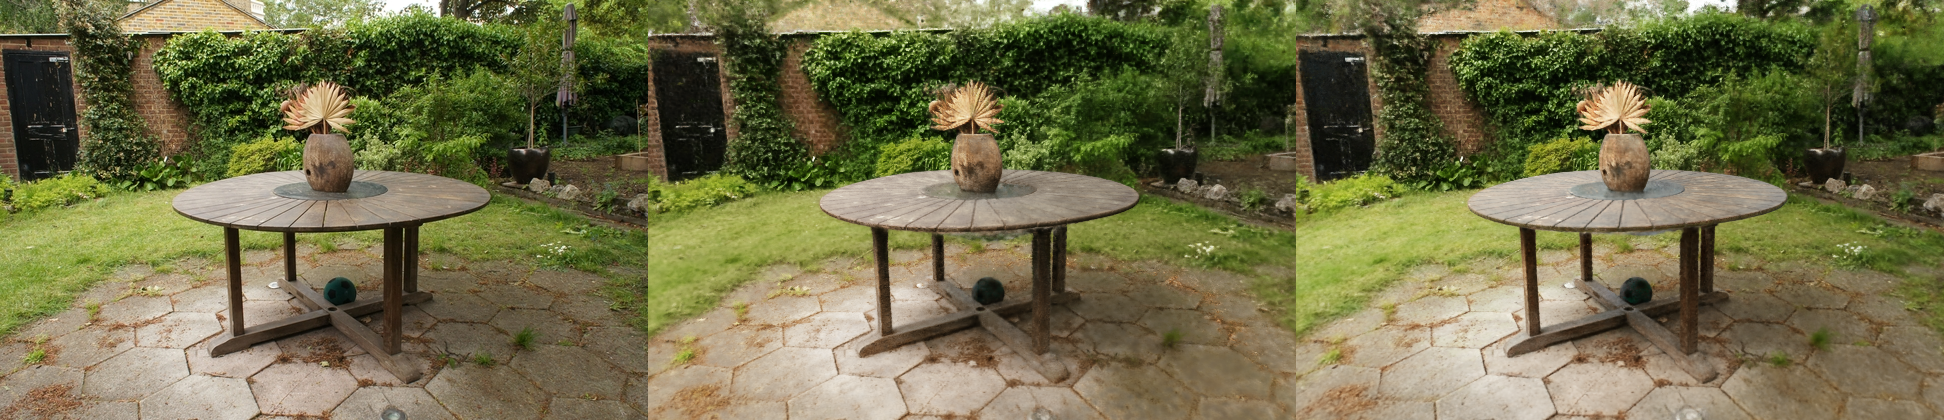

Visual comparison [Ground Truth | L=4 | L=8]: 0008_DSC08020.png


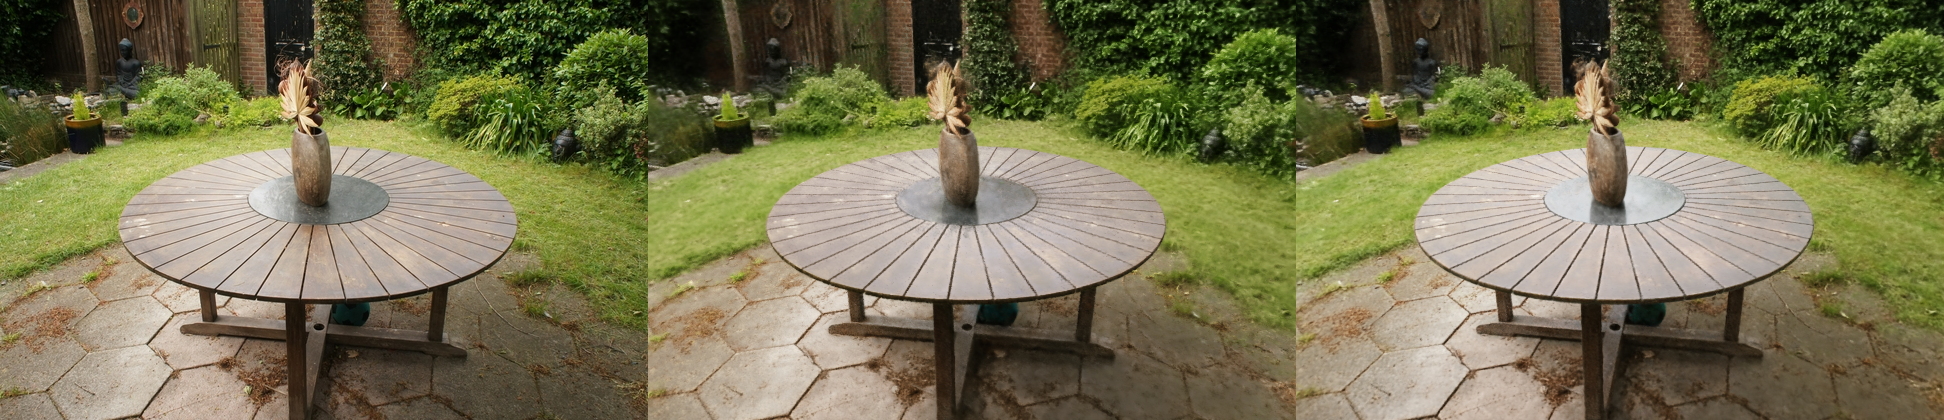

In [8]:
import json
from pathlib import Path

import pandas as pd
from IPython.display import display
from PIL import Image

tn1_ref = {
    "label": "TN1: Instant-NGP (mặc định, L=16, OGrid ON)",
    "method": "instant-ngp",
    "psnr_mean": 25.4221,
    "psnr_std": 1.763,
    "ssim_mean": 0.8182,
    "ssim_std": 0.0324,
    "lpips_mean": 0.1151,
    "lpips_std": 0.018,
    "training_seconds": 1528.37,
    "evaluation_seconds": 52.9,
    "mean_render_ms_per_image": 2006.49,
    "rays_per_second": 135639.57,
    "field_sample_queries_per_ray": 298.4597,
    "peak_gpu_memory_mib": 2736.76
}
m_l4 = json.loads((run_l4["artifacts"] / "evaluation" / "metrics.json").read_text(encoding="utf-8"))
m_l8 = json.loads((run_l8["artifacts"] / "evaluation" / "metrics.json").read_text(encoding="utf-8"))

ablation_table = pd.DataFrame([
    {
        "Cấu hình Hash Encoding": "TN4: Instant-NGP (L = 4)",
        "PSNR (dB)": f"{m_l4['psnr_mean']:.4f} ± {m_l4['psnr_std']:.4f}",
        "SSIM": f"{m_l4['ssim_mean']:.4f} ± {m_l4['ssim_std']:.4f}",
        "LPIPS": f"{m_l4['lpips_mean']:.4f} ± {m_l4['lpips_std']:.4f}",
        "Train (s)": f"{m_l4['training_seconds']:.2f}",
        "Render (ms/img)": f"{m_l4['mean_render_ms_per_image']:.2f}",
        "Queries/ray": f"{m_l4['field_sample_queries_per_ray']:.2f}",
        "Peak GPU (MiB)": f"{m_l4['peak_gpu_memory_mib']:.2f}",
        "Params": f"{m_l4['num_parameters']:,}",
        "Ckpt (MiB)": f"{m_l4['checkpoint_size_mib']:.2f}",
    },
    {
        "Cấu hình Hash Encoding": "TN4: Instant-NGP (L = 8)",
        "PSNR (dB)": f"{m_l8['psnr_mean']:.4f} ± {m_l8['psnr_std']:.4f}",
        "SSIM": f"{m_l8['ssim_mean']:.4f} ± {m_l8['ssim_std']:.4f}",
        "LPIPS": f"{m_l8['lpips_mean']:.4f} ± {m_l8['lpips_std']:.4f}",
        "Train (s)": f"{m_l8['training_seconds']:.2f}",
        "Render (ms/img)": f"{m_l8['mean_render_ms_per_image']:.2f}",
        "Queries/ray": f"{m_l8['field_sample_queries_per_ray']:.2f}",
        "Peak GPU (MiB)": f"{m_l8['peak_gpu_memory_mib']:.2f}",
        "Params": f"{m_l8['num_parameters']:,}",
        "Ckpt (MiB)": f"{m_l8['checkpoint_size_mib']:.2f}",
    },
    {
        "Cấu hình Hash Encoding": "TN1: Instant-NGP (L = 16, mặc định)",
        "PSNR (dB)": f"{tn1_ref['psnr_mean']:.4f} ± {tn1_ref['psnr_std']:.4f}",
        "SSIM": f"{tn1_ref['ssim_mean']:.4f} ± {tn1_ref['ssim_std']:.4f}",
        "LPIPS": f"{tn1_ref['lpips_mean']:.4f} ± {tn1_ref['lpips_std']:.4f}",
        "Train (s)": f"{tn1_ref['training_seconds']:.2f}",
        "Render (ms/img)": f"{tn1_ref['mean_render_ms_per_image']:.2f}",
        "Queries/ray": f"{tn1_ref['field_sample_queries_per_ray']:.2f}",
        "Peak GPU (MiB)": f"{tn1_ref['peak_gpu_memory_mib']:.2f}",
        "Params": "TN1 v27",
        "Ckpt (MiB)": "TN1 v27",
    },
])
print("=== TN4_HashEncoding Ablation Summary (L = 4 vs L = 8 vs L = 16) ===")
display(ablation_table)

print("\nPer-image metrics (L = 4):")
display(pd.read_csv(run_l4["artifacts"] / "evaluation" / "per-image-metrics.csv"))
print("\nPer-image metrics (L = 8):")
display(pd.read_csv(run_l8["artifacts"] / "evaluation" / "per-image-metrics.csv"))

# Visual comparison on representative held-out frames (Ground Truth | L=4 | L=8)
for sample_name in ["0000_DSC07956.png", "0008_DSC08020.png"]:
    p4 = run_l4["artifacts"] / "evaluation" / "comparisons" / sample_name
    p8 = run_l8["artifacts"] / "evaluation" / "comparisons" / sample_name
    if p4.is_file() and p8.is_file():
        im4 = Image.open(p4)
        im8 = Image.open(p8)
        w = im4.width // 2
        h = im4.height
        gt = im4.crop((0, 0, w, h))
        pred4 = im4.crop((w, 0, 2 * w, h))
        pred8 = im8.crop((w, 0, 2 * w, h))
        strip = Image.new("RGB", (w * 3, h))
        strip.paste(gt, (0, 0))
        strip.paste(pred4, (w, 0))
        strip.paste(pred8, (w * 2, 0))
        out_strip = Path("/kaggle/working/experiment-artifacts") / f"compare_L4_L8_{sample_name}"
        strip.save(out_strip)
        print(f"Visual comparison [Ground Truth | L=4 | L=8]: {sample_name}")
        display(strip)
